# Практическая работа № 8
## Статистические методы обнаружения аномалий в кибербезопасности

Решение выполнено на приложенном `cyber_statistical_anomalies.csv`. Выполняйте ячейки сверху вниз. Код снабжён подробными комментариями, а объяснения результатов находятся в текстовых ячейках.

`scenario` — учебная метка для проверки результата. Она **не участвует** в расчёте средних, порогов, ковариации и контрольных границ. Статистическая аномалия означает повод для проверки, а не доказанную атаку.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.covariance import MinCovDet

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

# CSV должен находиться рядом с блокнотом. Если его нет, не подменяем данные.
data_path = Path('cyber_statistical_anomalies.csv')
if not data_path.exists():
    raise FileNotFoundError('Положите cyber_statistical_anomalies.csv рядом с блокнотом')

### Загрузка данных

При чтении сразу преобразуем текстовое время в `datetime`. Это нужно для графиков и группировки по восьмичасовым окнам.

In [2]:
# parse_dates превращает строку вида «2026-03-01 00:00:00» в дату и время.
df = pd.read_csv(data_path, parse_dates=['timestamp'])
display(df.head())

,timestamp,user_id,failed_logins,bytes_out_mb,session_duration_min,connections_per_min,unique_destinations,requests_per_min,scenario
0,2026-03-01 00:00:00,user_01,2,13.67,41.46,112.58,8.27,100.82,normal
1,2026-03-01 01:00:00,user_02,1,5.50,22.04,94.50,8.99,116.07,normal
2,2026-03-01 02:00:00,user_03,3,7.23,17.02,127.99,15.70,103.22,normal
3,2026-03-01 03:00:00,user_04,1,34.82,43.01,128.34,13.26,108.67,normal
4,2026-03-01 04:00:00,user_05,3,26.91,44.50,92.45,13.33,93.48,normal


## Задание 1. Подготовка данных и постановка задачи

1. Выведите размер, типы столбцов, число пропусков и полных дубликатов.
2. Проверьте распределение учебных сценариев.
3. Укажите, какие внедрённые сценарии являются точечными, коллективными или многомерными.
4. Объясните, почему `scenario` нельзя использовать как входной признак.
5. Зафиксируйте базовый интервал `0:119` для многомерного профиля.

In [3]:
# Сначала проверяем структуру и качество входного файла.
print('Размер таблицы:', df.shape)
print('Типы столбцов:')
display(df.dtypes.to_frame('Тип'))
print('Число пропусков по столбцам:')
display(df.isna().sum().to_frame('Пропусков'))
print('Полных дубликатов:', int(df.duplicated().sum()))

# Базовый интервал 0:119 означает первые 120 строк.
baseline = df.iloc[:120].copy()
print('Базовый интервал: строки 0–119,', len(baseline), 'событий')
print('Время интервала:', baseline['timestamp'].min(), '—', baseline['timestamp'].max())

Размер таблицы: (240, 9)
Типы столбцов:


,Тип
timestamp,datetime64[ns]
user_id,object
failed_logins,int64
bytes_out_mb,float64
session_duration_min,float64
connections_per_min,float64
unique_destinations,float64
requests_per_min,float64
scenario,object


Число пропусков по столбцам:


,Пропусков
timestamp,0
user_id,0
failed_logins,0
bytes_out_mb,0
session_duration_min,0
connections_per_min,0
unique_destinations,0
requests_per_min,0
scenario,0


Полных дубликатов: 0
Базовый интервал: строки 0–119, 120 событий
Время интервала: 2026-03-01 00:00:00 — 2026-03-05 23:00:00


In [4]:
# scenario используется только для проверки: в пороги его не включаем.
scenario_counts = df['scenario'].value_counts()
display(scenario_counts.to_frame('Число событий'))

,Число событий
scenario,
normal,213
traffic_shift,20
brute_force,3
data_exfiltration,2
long_session,1
lateral_movement,1


### Вывод по заданию 1

В таблице 240 часовых событий и 9 исходных столбцов; пропусков и полных дубликатов нет. Из них 213 имеют метку `normal`, 20 — `traffic_shift`, 3 — `brute_force`, 2 — `data_exfiltration`, по одному — `long_session` и `lateral_movement`. Отдельные резкие значения входов, исходящего трафика и длительности сессии — примеры точечных аномалий; 20 последовательных часов `traffic_shift` — коллективная аномалия; `lateral_movement` следует оценивать по сочетанию двух сетевых признаков, то есть как многомерную аномалию. Это учебная классификация: одна и та же строка может быть заметна несколькими методами. `scenario` известен только для учебной проверки и при включении в расчёт сообщил бы методу ответ заранее. Первые 120 строк (с 1 марта 00:00 до 5 марта 23:00) служат опорным интервалом для многомерного профиля, хотя в них уже встречаются внедрённые сценарии; это ограничивает качество оценки фона.

## Задание 2. Одномерные пороговые методы

1. Для `failed_logins` вычислите Z-score и отметьте значения `z > 3`.
2. Для `bytes_out_mb` вычислите границы IQR с коэффициентом 1,5.
3. Для того же признака вычислите модифицированный Z-score с порогом `|M| > 3.5`.
4. Рассчитайте верхний квантиль 0,995.
5. Сравните списки событий и объясните ложные срабатывания IQR/MAD на правосторонне асимметричном распределении.
6. Постройте график Z-score и boxplot для исходящего трафика.

In [5]:
# Z-score показывает, на сколько стандартных отклонений значение выше среднего.
# Для задания ищем только большие значения failed_logins, поэтому проверяем z > 3.
feature = 'failed_logins'
mean_value = df[feature].mean()
std_value = df[feature].std(ddof=1)
if std_value == 0:
    raise ValueError('Стандартное отклонение failed_logins равно нулю')

df['failed_logins_z'] = (df[feature] - mean_value) / std_value
df['z_anomaly'] = df['failed_logins_z'] > 3

print('Среднее:', round(mean_value, 3), '| стандартное отклонение:', round(std_value, 3))
print('Событий с z > 3:', int(df['z_anomaly'].sum()))
display(df.loc[df['z_anomaly'],
               ['timestamp', feature, 'failed_logins_z', 'scenario']])

Среднее: 1.342 | стандартное отклонение: 1.879
Событий с z > 3: 3


,timestamp,failed_logins,failed_logins_z,scenario
37,2026-03-02 13:00:00,12,5.671805,brute_force
148,2026-03-07 04:00:00,15,7.268248,brute_force
219,2026-03-10 03:00:00,18,8.864690,brute_force


In [6]:
feature = 'bytes_out_mb'

# IQR — разница между 75-м и 25-м процентилями.
# Классическое правило 1,5 × IQR отмечает значения за обеими границами.
q1 = df[feature].quantile(0.25)
q3 = df[feature].quantile(0.75)
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
df['iqr_anomaly'] = (df[feature] < lower_limit) | (df[feature] > upper_limit)

# MAD — медиана абсолютных отклонений от медианы.
# Коэффициент 0.6745 переводит MAD в масштаб обычного Z-score при нормальности.
median_value = df[feature].median()
mad = (df[feature] - median_value).abs().median()
if mad == 0:
    raise ValueError('MAD равен нулю: модифицированный Z-score не определён')
df['modified_z'] = 0.6745 * (df[feature] - median_value) / mad
df['mad_anomaly'] = df['modified_z'].abs() > 3.5

# Квантиль 0.995 — высокий порог для верхнего хвоста.
quantile_level = 0.995
quantile_limit = df[feature].quantile(quantile_level)
df['quantile_anomaly'] = df[feature] > quantile_limit

print('IQR: Q1 =', round(q1, 2), ', Q3 =', round(q3, 2),
      ', нижняя граница =', round(lower_limit, 2),
      ', верхняя граница =', round(upper_limit, 2))
print('MAD: медиана =', round(median_value, 2), ', MAD =', round(mad, 2))
print('Квантиль 0.995:', round(quantile_limit, 2))

IQR: Q1 = 10.33 , Q3 = 22.34 , нижняя граница = -7.69 , верхняя граница = 40.35
MAD: медиана = 15.07 , MAD = 5.74
Квантиль 0.995: 351.13


,Метод,Число событий,Сценарии среди найденных
0,Z-score входов,3,{'brute_force': 3}
1,IQR трафика,11,"{'normal': 8, 'data_exfiltration': 2, 'traffic..."
2,MAD трафика,9,"{'normal': 6, 'data_exfiltration': 2, 'traffic..."
3,Квантиль трафика,2,{'data_exfiltration': 2}


,timestamp,failed_logins,bytes_out_mb,scenario,z_anomaly,iqr_anomaly,mad_anomaly,quantile_anomaly
9,2026-03-01 09:00:00,1,62.25,normal,False,True,True,False
37,2026-03-02 13:00:00,12,6.95,brute_force,True,False,False,False
56,2026-03-03 08:00:00,0,50.36,normal,False,True,True,False
80,2026-03-04 08:00:00,1,420.00,data_exfiltration,False,True,True,True
88,2026-03-04 16:00:00,0,49.33,normal,False,True,True,False
95,2026-03-04 23:00:00,0,44.78,normal,False,True,False,False
134,2026-03-06 14:00:00,0,66.83,normal,False,True,True,False
145,2026-03-07 01:00:00,1,50.85,normal,False,True,True,False
148,2026-03-07 04:00:00,15,15.21,brute_force,True,False,False,False
153,2026-03-07 09:00:00,1,45.44,normal,False,True,True,False


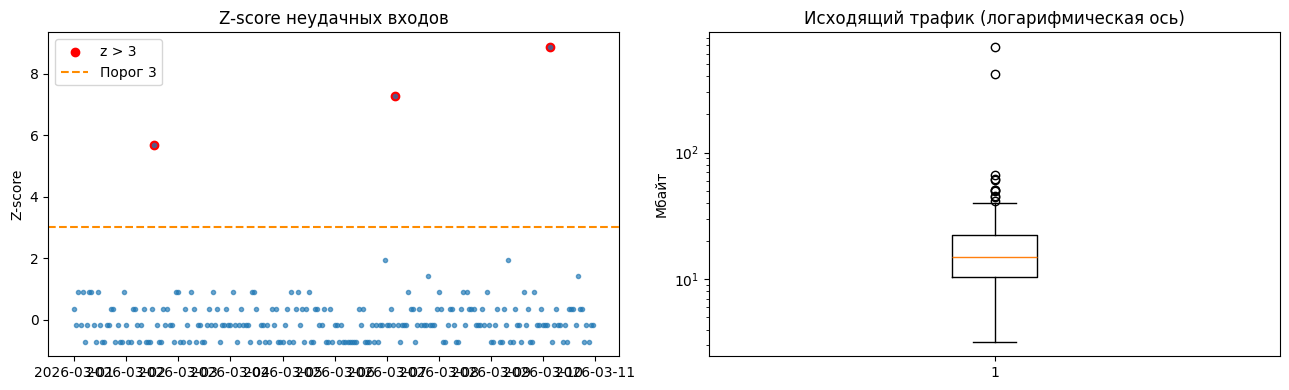

In [7]:
# Сводим флаги в одну таблицу. Метки сценариев читаем только после расчёта.
methods = {
    'Z-score входов': 'z_anomaly',
    'IQR трафика': 'iqr_anomaly',
    'MAD трафика': 'mad_anomaly',
    'Квантиль трафика': 'quantile_anomaly'
}
comparison_rows = []
for name, flag in methods.items():
    selected = df.loc[df[flag]]
    comparison_rows.append({
        'Метод': name,
        'Число событий': len(selected),
        'Сценарии среди найденных': selected['scenario'].value_counts().to_dict()
    })
comparison = pd.DataFrame(comparison_rows)
display(comparison)

# Каждая строка ниже — событие, найденное хотя бы одним из методов.
flags = list(methods.values())
alerts = df.loc[df[flags].any(axis=1),
                ['timestamp', 'failed_logins', 'bytes_out_mb', 'scenario', *flags]]
display(alerts)

# Первый график показывает отдельные события с z > 3.
# Второй показывает асимметрию исходящего трафика и редкие крупные значения.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(df['timestamp'], df['failed_logins_z'], '.', alpha=0.65)
axes[0].scatter(df.loc[df['z_anomaly'], 'timestamp'],
                df.loc[df['z_anomaly'], 'failed_logins_z'], color='red', label='z > 3')
axes[0].axhline(3, color='darkorange', linestyle='--', label='Порог 3')
axes[0].set_title('Z-score неудачных входов')
axes[0].set_ylabel('Z-score')
axes[0].legend()

axes[1].boxplot(df['bytes_out_mb'])
axes[1].set_yscale('log')
axes[1].set_title('Исходящий трафик (логарифмическая ось)')
axes[1].set_ylabel('Мбайт')
plt.tight_layout()
plt.show()

### Вывод по заданию 2

Для `failed_logins` порог `z > 3` нашёл все три события `brute_force`: 12, 15 и 18 неудачных входов. Для `bytes_out_mb` IQR нашёл 11 событий, MAD — 9, а квантиль 0,995 — только два наибольших значения: 420 и 680 Мбайт, оба с меткой `data_exfiltration`. У IQR восемь находок помечены `normal`, у MAD — шесть: правый хвост исходящего трафика длинный, поэтому обычные для такого распределения крупные значения могут выходить за пороги, рассчитанные по центральной части данных. Это ложные срабатывания относительно учебных меток, но их реальную безопасность надо подтверждать контекстом. Квантиль оказался точнее на данном наборе, однако порог оценён по тем же данным, которые проверяются, и чувствительность к менее крупным утечкам не доказана.

## Задание 3. Критерий Граббса

**H₀:** все наблюдения длительности взяты из одного приблизительно нормального распределения без единственного выброса. **H₁:** наблюдение с наибольшим отклонением от среднего является выбросом. Тест чувствителен к предположению о нормальности и рассчитан на одну крайнюю точку за один запуск.

In [8]:
def grubbs_test(values, alpha=0.05):
    # Приводим значения к массиву чисел и считаем основные статистики.
    values = np.asarray(values, dtype=float)
    n = len(values)
    if n < 3:
        raise ValueError('Для критерия Граббса нужно хотя бы три значения')
    mean = values.mean()
    std = values.std(ddof=1)
    if std == 0:
        raise ValueError('Все значения одинаковы')

    # Ищем одно наблюдение с максимальным отклонением от среднего.
    deviations = np.abs(values - mean)
    index = int(np.argmax(deviations))
    g_value = deviations[index] / std

    # Поправка alpha/(2n) учитывает поиск максимума среди n точек и две стороны.
    t_critical = stats.t.ppf(1 - alpha / (2 * n), df=n - 2)
    g_critical = (n - 1) / np.sqrt(n) * np.sqrt(
        t_critical ** 2 / (n - 2 + t_critical ** 2)
    )
    return {
        'индекс': index,
        'значение': values[index],
        'G': g_value,
        'Gcrit': g_critical,
        'отвергнуть H0': bool(g_value > g_critical)
    }

result = grubbs_test(df['session_duration_min'], alpha=0.05)
display(pd.Series(result, name='Критерий Граббса').to_frame())
display(df.loc[[result['индекс']],
               ['timestamp', 'session_duration_min', 'scenario']])

,Критерий Граббса
индекс,112
значение,92.0
G,6.310242
Gcrit,3.659494
отвергнуть H0,True


,timestamp,session_duration_min,scenario
112,2026-03-05 16:00:00,92.0,long_session


### Решение по гипотезе

При `α = 0,05` получено `G = 6,310`, что больше `Gcrit = 3,659`, поэтому отвергаем H₀ для наиболее удалённого наблюдения. Это строка 112 от 5 марта 16:00 с длительностью сессии 92 минуты (`long_session`). Критерий Граббса предполагает приблизительную нормальность исходной выборки и проверяет одну крайнюю точку за один запуск. Если удалять найденные точки и повторять тест без поправки на множественные проверки, вероятность хотя бы одного ложного вывода возрастёт.

## Задание 4. Многомерные аномалии

1. На базовом интервале `0:119` оцените средний вектор и ковариационную матрицу для `connections_per_min` и `unique_destinations`.
2. Рассчитайте квадрат расстояния Махаланобиса для всех наблюдений.
3. Используйте порог χ² уровня 0,99 при двух степенях свободы.
4. Повторите расчёт с `MinCovDet(random_state=42)`.
5. Сравните найденные события и объясните назначение робастной оценки.
6. Постройте диаграмму рассеяния и выделите аномалии классического метода.

In [9]:
# Базовый профиль строим только по строкам 0–119.
# scenario не используется ни для среднего, ни для ковариации.
features = ['connections_per_min', 'unique_destinations']
reference_data = df.iloc[:120][features]
mean_vector = reference_data.mean().to_numpy()
covariance_matrix = reference_data.cov().to_numpy()
inverse_covariance = np.linalg.inv(covariance_matrix)

# Для каждой точки сначала вычитаем средний вектор, затем считаем d².
classical_distances = []
for values in df[features].to_numpy():
    difference = values - mean_vector
    distance_squared = difference @ inverse_covariance @ difference
    classical_distances.append(distance_squared)
df['mahalanobis_d2'] = classical_distances

# Для двух признаков берём 99-й процентиль распределения χ² с 2 степенями свободы.
mahalanobis_limit = stats.chi2.ppf(0.99, df=2)
df['mahalanobis_anomaly'] = df['mahalanobis_d2'] > mahalanobis_limit

print('Средний вектор базового интервала:')
display(pd.Series(mean_vector, index=features, name='Среднее'))
print('Ковариационная матрица:')
display(pd.DataFrame(covariance_matrix, index=features, columns=features))
print('Порог d²:', round(mahalanobis_limit, 3))

Средний вектор базового интервала:


connections_per_min    121.165833
unique_destinations     12.805500
Name: Среднее, dtype: float64

Ковариационная матрица:


,connections_per_min,unique_destinations
connections_per_min,265.098830,15.859532
unique_destinations,15.859532,4.497423


Порог d²: 9.21


In [10]:
# MinCovDet ищет устойчивые центр и ковариацию по тому же базовому интервалу.
# Так отдельные необычные строки меньше влияют на параметры профиля.
robust_model = MinCovDet(random_state=42)
robust_model.fit(reference_data)

# Метод mahalanobis уже возвращает квадрат расстояния.
df['robust_mahalanobis_d2'] = robust_model.mahalanobis(df[features])
df['robust_mahalanobis_anomaly'] = (
    df['robust_mahalanobis_d2'] > mahalanobis_limit
)

,Метод,Число событий,Сценарии среди найденных
0,Классический,6,"{'normal': 4, 'lateral_movement': 1, 'traffic_..."
1,Робастный MCD,11,"{'normal': 8, 'lateral_movement': 1, 'traffic_..."


Классический метод нашёл:


,timestamp,connections_per_min,unique_destinations,mahalanobis_d2,scenario
76,2026-03-04 04:00:00,164.01,11.83,10.452999,normal
100,2026-03-05 04:00:00,170.57,16.76,9.488203,normal
121,2026-03-06 01:00:00,148.00,9.50,9.512245,lateral_movement
164,2026-03-07 20:00:00,78.25,4.93,14.887315,traffic_shift
220,2026-03-10 04:00:00,103.32,6.40,9.230612,normal
237,2026-03-10 21:00:00,72.27,12.34,10.723442,normal


Только робастный метод нашёл:


,timestamp,connections_per_min,unique_destinations,robust_mahalanobis_d2,scenario
91,2026-03-04 19:00:00,146.01,9.49,10.698034,normal
181,2026-03-08 13:00:00,75.88,10.97,10.528961,data_exfiltration
189,2026-03-08 21:00:00,164.23,16.14,9.453090,normal
194,2026-03-09 02:00:00,85.65,14.58,10.946478,normal
239,2026-03-10 23:00:00,87.41,14.82,10.648395,normal


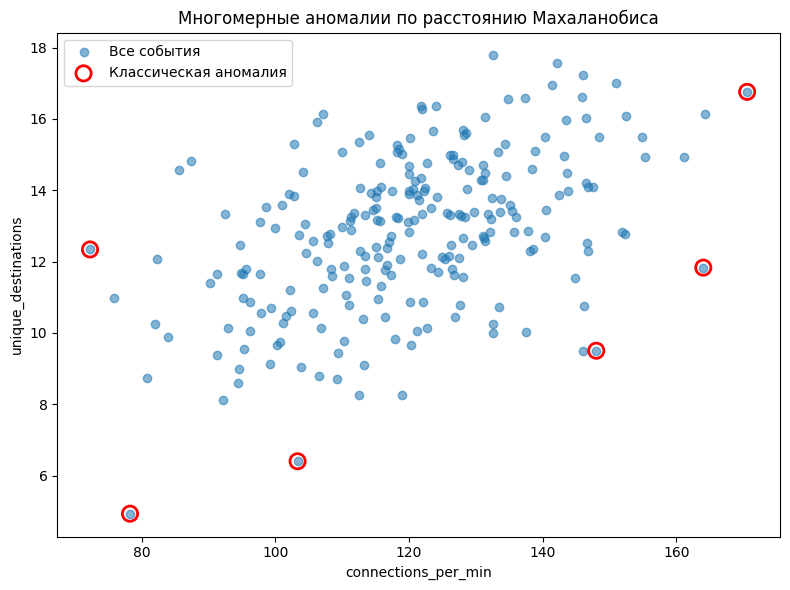

In [11]:
# Сравниваем число и состав найденных событий.
multivariate_comparison = pd.DataFrame({
    'Метод': ['Классический', 'Робастный MCD'],
    'Число событий': [
        int(df['mahalanobis_anomaly'].sum()),
        int(df['robust_mahalanobis_anomaly'].sum())
    ],
    'Сценарии среди найденных': [
        df.loc[df['mahalanobis_anomaly'], 'scenario'].value_counts().to_dict(),
        df.loc[df['robust_mahalanobis_anomaly'], 'scenario'].value_counts().to_dict()
    ]
})
display(multivariate_comparison)

print('Классический метод нашёл:')
display(df.loc[df['mahalanobis_anomaly'],
               ['timestamp', *features, 'mahalanobis_d2', 'scenario']])
print('Только робастный метод нашёл:')
only_robust = df['robust_mahalanobis_anomaly'] & ~df['mahalanobis_anomaly']
display(df.loc[only_robust,
               ['timestamp', *features, 'robust_mahalanobis_d2', 'scenario']])

# Цвет окружности показывает результат классического метода.
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df[features[0]], df[features[1]], alpha=0.55, label='Все события')
ax.scatter(df.loc[df['mahalanobis_anomaly'], features[0]],
           df.loc[df['mahalanobis_anomaly'], features[1]],
           facecolors='none', edgecolors='red', s=120, linewidth=2,
           label='Классическая аномалия')
ax.set_xlabel(features[0])
ax.set_ylabel(features[1])
ax.set_title('Многомерные аномалии по расстоянию Махаланобиса')
ax.legend()
plt.tight_layout()
plt.show()

### Вывод по заданию 4

При пороге `χ²(2; 0,99) = 9,210` классическое расстояние нашло 6 событий, робастное — 10. Оба метода выделили строку 121 от 6 марта 01:00 (`lateral_movement`): 148 соединений в минуту при 9,50 уникальных назначениях — необычное сочетание относительно базового профиля. Классический метод также отметил одну строку `traffic_shift` и четыре `normal`; робастный добавил четыре строки, в том числе одну `data_exfiltration`, потому что его оценка центра и ковариации меньше зависит от крайних значений в базовом интервале. Робастность не делает каждый дополнительный сигнал подтверждённой атакой: семь из десяти его находок имеют учебную метку `normal`. При интерпретации нужно учитывать, что базовый интервал содержит несколько внедрённых событий и что порог χ² является приближением при соответствующей модели распределения.

## Задание 5. Контрольные карты Шухарта и записка SOC

1. Разбейте `requests_per_min` на 8-часовые окна.
2. Рассчитайте по окнам среднее и стандартное отклонение.
3. Для X-bar и R-карты вычислите CL, UCL и LCL по правилу 3σ. Для R-карты ограничьте LCL снизу нулём.
4. Найдите окна выше UCL и постройте две контрольные карты.
5. Подготовьте аналитическую записку SOC из 5–7 предложений.

In [12]:
# Каждая строка — один час, поэтому восемь строк образуют 8-часовое окно.
df['window'] = df['timestamp'].dt.floor('8h')

# Сохраняем и стандартное отклонение, и размах max-min.
# В задании требуется статистика std; для собственно R-карты используем размах R.
grouped = df.groupby('window')['requests_per_min'].agg(
    mean='mean', std='std', minimum='min', maximum='max', count='count'
)
grouped['range'] = grouped['maximum'] - grouped['minimum']

# Простой учебный вариант 3σ: среднее статистики по окнам ± 3 её std по окнам.
# Оценки получены по всем окнам, поэтому сдвиг может повлиять на границы.
cl_mean = grouped['mean'].mean()
sigma_mean = grouped['mean'].std(ddof=1)
ucl_mean = cl_mean + 3 * sigma_mean
lcl_mean = cl_mean - 3 * sigma_mean

cl_range = grouped['range'].mean()
sigma_range = grouped['range'].std(ddof=1)
ucl_range = cl_range + 3 * sigma_range
lcl_range = max(0, cl_range - 3 * sigma_range)

limits = pd.DataFrame({
    'Карта': ['X-bar (среднее)', 'R (размах)'],
    'CL': [cl_mean, cl_range],
    'LCL': [lcl_mean, lcl_range],
    'UCL': [ucl_mean, ucl_range]
})
display(limits.round(3))
print('Число восьмичасовых окон:', len(grouped))
display(grouped.head())

,Карта,CL,LCL,UCL
0,X-bar (среднее),101.812,68.815,134.808
1,R (размах),27.384,0.000,55.231


Число восьмичасовых окон: 30


,mean,std,minimum,maximum,count,range
window,,,,,,
2026-03-01 00:00:00,103.45250,7.990521,92.32,116.07,8,23.75
2026-03-01 08:00:00,94.84875,9.206874,84.09,110.13,8,26.04
2026-03-01 16:00:00,99.76250,13.149529,79.66,118.86,8,39.20
2026-03-02 00:00:00,100.91000,7.121870,87.64,107.90,8,20.26
2026-03-02 08:00:00,96.30000,4.866521,90.06,102.91,8,12.85


Окна выше UCL X-bar:


,mean,std,range
window,,,
2026-03-07 16:00:00,138.61000,8.428020,26.57
2026-03-08 00:00:00,137.91625,12.174372,35.41


Окна выше UCL R:


,mean,std,range
window,,,
2026-03-08 08:00:00,117.75375,22.61674,61.0


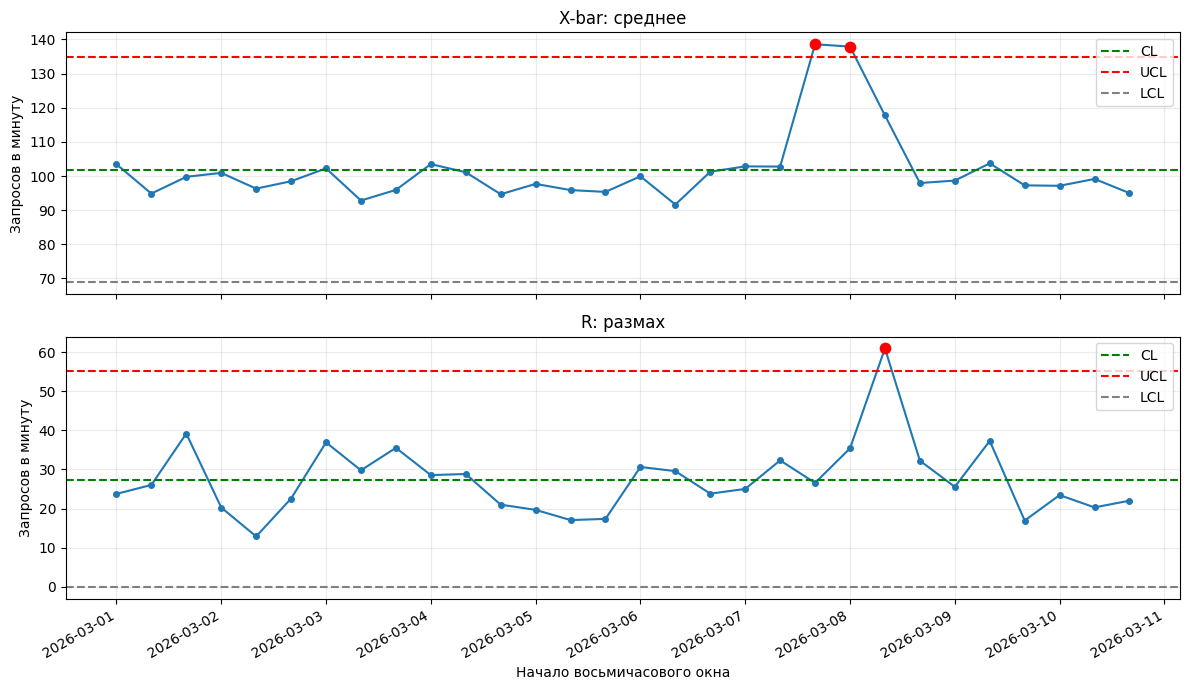

In [13]:
# Проверяем выход за верхнюю границу для обеих карт.
grouped['xbar_high'] = grouped['mean'] > ucl_mean
grouped['r_high'] = grouped['range'] > ucl_range
print('Окна выше UCL X-bar:')
display(grouped.loc[grouped['xbar_high'], ['mean', 'std', 'range']])
print('Окна выше UCL R:')
display(grouped.loc[grouped['r_high'], ['mean', 'std', 'range']])

# Верхняя и нижняя линии — контрольные границы, красные точки — превышения UCL.
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, column, cl, lcl, ucl, flag, title in [
    (axes[0], 'mean', cl_mean, lcl_mean, ucl_mean, 'xbar_high', 'X-bar: среднее'),
    (axes[1], 'range', cl_range, lcl_range, ucl_range, 'r_high', 'R: размах')
]:
    ax.plot(grouped.index, grouped[column], marker='o', markersize=4)
    ax.axhline(cl, color='green', linestyle='--', label='CL')
    ax.axhline(ucl, color='red', linestyle='--', label='UCL')
    ax.axhline(lcl, color='gray', linestyle='--', label='LCL')
    ax.scatter(grouped.index[grouped[flag]], grouped.loc[grouped[flag], column],
               color='red', s=55, zorder=3)
    ax.set_title(title)
    ax.set_ylabel('Запросов в минуту')
    ax.legend()
    ax.grid(alpha=0.25)
axes[-1].set_xlabel('Начало восьмичасового окна')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Записка SOC

Проанализированы 240 часовых событий с 1 марта 00:00 по 10 марта 23:00 2026 года; `scenario` использован только для проверки результатов. Порог `z > 3` выявил три всплеска неудачных входов (12, 15 и 18), квантиль 0,995 выделил исходящий трафик 420 и 680 Мбайт, а критерий Граббса при `α = 0,05` отметил сессию длительностью 92 минуты. Классическое расстояние Махаланобиса с порогом `d² > 9,210` выделило шесть событий, включая сочетание 148 соединений в минуту и 9,50 уникальных назначений 6 марта 01:00. На X-bar-карте с верхней границей 134,808 запросов в минуту отмечены окна 7 марта 16:00–23:00 (среднее 138,61) и 8 марта 00:00–07:00 (137,92); R-карта с верхней границей 55,231 отметила окно 8 марта 08:00–15:00 (размах 61,00). Эти отклонения требуют проверки журналов аутентификации, сетевых назначений и объёма передачи по пользователям, а для сдвига запросов — сопоставления с изменениями нагрузки и расписанием работ. Пороги IQR и MAD дали соответственно восемь и шесть находок с меткой `normal`, поэтому их сигналы необходимо сверять с контекстом и не приравнивать к атакам. Контрольные границы оценены по всему периоду, включая сдвиг, а базовый многомерный интервал содержит внедрённые события; для реального мониторинга желательно переоценить фон на проверенном спокойном периоде и проверить предпосылки статистических методов.